# TWO-DIMENSIONAL TOY EXAMPLES

In [1]:
import warnings
warnings.filterwarnings('ignore')

import math, time
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from dataclasses import dataclass
import numpy as np
import pandas as pd
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from functools import partial
from tqdm import tqdm as _tqdm
from sklearn.datasets import make_swiss_roll
from sklearn.neighbors import NearestNeighbors

tqdm = partial(_tqdm, disable=True)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset'] = 'cm'

DEVICES = ['cuda:0']
DEVICE = DEVICES[0]
SEEDS = [0, 1, 2]
NFES = [1, 2, 4, 8, 16, 32]
N_TRAIN, EVAL_N, BS, D = 20000, 5000, 512, 2
EPOCHS = 600
K_EXP = 16  # number of experts in MDLM-MoE and E-MoE
N_TV, N_REF = 20000, 200000  # TV: model samples vs a large reference draw from the same generator
DATASET_NAMES = ['8modes', 'swiss_roll', 'checkerboard']
ABLATION_DATASET = '8modes'
RESULTS_DIR = 'toy_results'  # checkpoints + metrics of every run

print(torch.__version__)
import json

2.3.1+cu121


## Data

In [2]:
def _cont2disc(x, V, qrange=(-3, 3)):
    edges = torch.linspace(qrange[0], qrange[1], V - 1)
    if isinstance(x, np.ndarray):
        x = torch.tensor(x)
    return torch.bucketize(x, edges)


def gen_8modes(n, seed, V=50, D=2, M=8, sigma=0.09):
    """M gaussian modes in R^D."""
    rng = np.random.RandomState(seed)
    centers = rng.uniform(-2.5, 2.5, size=(M, D))
    idx = rng.randint(0, M, size=n)
    pts = centers[idx] + sigma * rng.randn(n, D)
    gen_8modes.centers = centers
    return _cont2disc(pts, V).long(), idx


def gen_swiss_roll(n, seed, V=50, D=2, M=None):
    """Swiss-roll 2D manifold lifted into D ambient dims."""
    base = make_swiss_roll(n_samples=n, noise=0.45, random_state=seed)[0][:, [0, 2]] / 7.5
    if D == 2:
        raw = base
    else:
        rng = np.random.RandomState(seed + 777)
        W = rng.randn(2, D); W /= np.linalg.norm(W, axis=0, keepdims=True)
        raw = base @ W
    return _cont2disc(raw, V).long(), None


def gen_checkerboard(n, seed, V=50, D=2, M=None):
    """4x4 checkerboard: uniform on 8 of the 16 squares."""
    rng = np.random.RandomState(seed)
    x1 = rng.rand(n) * 4 - 2
    x2 = rng.rand(n) - rng.randint(0, 2, size=n) * 2 + np.floor(x1) % 2
    pts = 1.25 * np.stack([x1, x2], axis=1)
    return _cont2disc(pts, V).long(), None


DATASETS = {
    'swiss_roll': dict(gen=gen_swiss_roll, V=50, M=None, spatial=True),
    '8modes': dict(gen=gen_8modes, V=50, M=8, spatial=True),
    'checkerboard': dict(gen=gen_checkerboard, V=50, M=None, spatial=True),
}


def support_validity(samples, train, sub=3000):
    tr = train[:sub].astype(np.float64)
    nn = NearestNeighbors(n_neighbors=2).fit(tr)
    dtr, _ = nn.kneighbors(tr)
    thr = float(np.percentile(dtr[:, 1], 90))
    ds, _ = nn.kneighbors(samples[:sub].astype(np.float64))
    return float((ds[:, 0] <= thr).mean())

## GT data visualization (8-modes, Swiss-roll, Checkerboard)

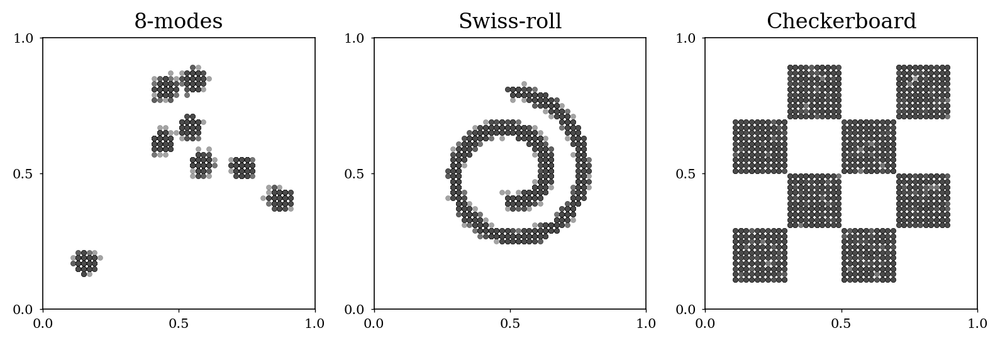

In [3]:
GT_COLOR = '#4a4a4a'
C_MDLM = '#D98C86'
C_VADD = '#8FB5DC'
C_MOE = '#C9A227'
C_EMOE = '#1F4E8C'

%config InlineBackend.figure_format = 'retina'

def _undiscretise(tok, V):
    if isinstance(tok, torch.Tensor):
        tok = tok.cpu().numpy()
    return (tok.astype(np.float64) + 0.5) / V


DATASET_LABELS = {'8modes': '8-modes', 'swiss_roll': 'Swiss-roll', 'checkerboard': 'Checkerboard'}
N_SHOW, cell = 6000, 5.2


S = 0.5 
cell = 5.2 * S
fig, axes = plt.subplots(1, 3, figsize=(cell * 3 + 0.5 * S, cell + 0.8 * S))
for ax, ds_name in zip(axes, DATASET_NAMES):
    ds = DATASETS[ds_name]
    tokens, _ = ds['gen'](20000, 0, V=ds['V'], D=2, M=ds['M'])
    xy = _undiscretise(tokens[:N_SHOW], ds['V'])
    ax.scatter(xy[:, 0], xy[:, 1], s=34 * S**2, alpha=0.5, c=GT_COLOR,
                edgecolors='black', linewidths=0.25 * S, rasterized=True)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(labelsize=15 * S, width=S, length=3.5 * S)
    ax.set_aspect('equal')
    ax.set_title(DATASET_LABELS[ds_name], fontsize=24 * S, pad=11 * S)
    for sp in ax.spines.values():
        sp.set_edgecolor('black'); sp.set_linewidth(1.2 * S)
plt.tight_layout()
plt.show()

## Model

All methods use the same backbone, simple Transformer implementation

In [4]:
@dataclass
class C:
    V: int # vocab size (without MASK token)
    L: int # seq length
    H: int = 128
    SIN: int = 64
    K: int = 8 # num experts in E-MoE
    topk: int = 2
    routing_mode: str = 'sequence_level' # routing mode: 'per_token' or 'sequence_level'
    det_routing: bool = False # MDLM-MoE: deterministic top-1 routing from x_t (no latent)
    n_layers: int = 2
    n_heads: int = 4
    mlp_ratio: int = 4
    bs: int = 512 # batch size
    lr: float = 3e-4 # learning rate
    epochs: int = 300
    diffusion_steps: int = 64
    kl_weight: float = 1.0
    lb_weight: float = 0.1 # load-balancing loss weight in MDLM-MoE
    gumbel_tau_init: float = 1.0
    gumbel_tau_min: float = 0.1
    gumbel_tau_anneal_rate: float = 3e-5

    @property
    def MASK(self):
        return self.V

def alpha(t):
    return 1.0 - t

def sample_xt(x0, t, MASK):
    keep = torch.rand_like(x0.float()) < alpha(t)[:, None]
    return torch.where(keep, x0, torch.full_like(x0, MASK))

def sin_embed(t, dim=64):
    half = dim // 2
    f = torch.exp(torch.linspace(0, math.log(1000), half, device=t.device))
    a = t[:, None] * f[None]
    return torch.cat([a.sin(), a.cos()], dim=-1)


class TransformerBlock(nn.Module):
    def __init__(self, H, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(H)
        self.norm2 = nn.LayerNorm(H)
        self.attn = nn.MultiheadAttention(H, n_heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(H, mlp_ratio * H), nn.GELU(),
                                 nn.Linear(mlp_ratio * H, H))

    def forward(self, x):
        # x here is (B, L, H), where B - batch size, L - seq.len (=2 [x, y]), H - hidden dim
        n1 = self.norm1(x)
        a, _ = self.attn(n1, n1, n1, need_weights=False)
        x = x + a # residual connection
        return x + self.mlp(self.norm2(x)) # mlp then again residual connection

 ### MoE block

The MLP is replaced by $K$ experts with a router. 

- In **E-MoE** the route is a latent: top-2 Gumbel-softmax with a STE hard decision of one expert,
either per token (`per_token`) or one route per sequence and layer (`sequence_level`: the router reads the mean-pooled hidden state, so the whole $(x, y)$ pair shares the route). 

- In **MDLM-MoE** the route is a deterministic function of $x_t$: top-1 expert scaled by its gate probability (Switch-style), no latent and no KL.

In [5]:
def topk_gumbel_ste(routing_logits, K, topk, tau):
    # gumbel-softmax for router logits
    w = F.gumbel_softmax(routing_logits.float(), tau=tau, hard=False, dim=-1)
    # normalization
    sel_w, sel_e = w.topk(topk, dim=-1)
    sel_w = sel_w / (sel_w.sum(dim=-1, keepdim=True) + 1e-8)
    # one-hot vector with STE trick
    hard_idx = sel_w.argmax(dim=-1, keepdim=True)
    hard_w_topk = torch.zeros_like(sel_w).scatter_(-1, hard_idx, 1.0)
    hard_w = (hard_w_topk - sel_w).detach() + sel_w
    full_w = torch.zeros_like(routing_logits.float())
    full_w.scatter_(-1, sel_e, hard_w)
    active = torch.zeros_like(full_w, dtype=torch.bool)
    if torch.is_grad_enabled():
        active.scatter_(-1, sel_e, True)
    else:
        active.scatter_(-1, sel_e.gather(-1, hard_idx), True)
        full_w = active.float()
    return full_w, active


def top1_det(routing_logits):
    """Deterministic Switch-style routing: argmax expert, weighted by its gate probability."""
    p = F.softmax(routing_logits.float(), dim=-1)
    idx = p.argmax(dim=-1, keepdim=True)
    active = torch.zeros_like(p, dtype=torch.bool).scatter_(-1, idx, True)
    full_w = torch.zeros_like(p).scatter_(-1, idx, p.gather(-1, idx))
    return full_w, active


class MoEBlock(nn.Module):
    def __init__(self, H, n_heads, mlp_ratio=4, K=8, topk=2, routing_mode='per_token', det_routing=False):
        super().__init__()
        self.det_routing = det_routing
        self.K = K
        self.topk = topk
        self.routing_mode = routing_mode
        self.norm1 = nn.LayerNorm(H)
        self.norm2 = nn.LayerNorm(H)
        self.attn = nn.MultiheadAttention(H, n_heads, batch_first=True)
        self.experts = nn.ModuleList([
            nn.Sequential(nn.Linear(H, mlp_ratio * H), nn.GELU(),
                          nn.Linear(mlp_ratio * H, H)) for _ in range(K)])
        self.router = nn.Linear(H, K, bias=False)
        nn.init.normal_(self.router.weight, std=0.02)

    def _sparse_moe(self, h, full_w, active):
        if torch.is_grad_enabled():
            all_outs = torch.stack([e(h) for e in self.experts], dim=0)
            return torch.einsum("kblh,blk->blh", all_outs, full_w.to(all_outs.dtype))
        B, L, H = h.shape
        hf, wf, af = h.reshape(-1, H), full_w.reshape(-1, self.K).to(h.dtype), active.reshape(-1, self.K)
        out = torch.zeros_like(hf)
        for e, expert in enumerate(self.experts):
            idx = af[:, e].nonzero(as_tuple=True)[0]
            if idx.numel() > 0:
                out = out.index_add(0, idx, expert(hf[idx]) * wf[idx, e:e + 1])
        return out.view(B, L, H)

    def forward(self, x, force_route=None, tau=1.0):
        n1 = self.norm1(x)
        a, _ = self.attn(n1, n1, n1, need_weights=False)
        x = x + a
        h_pre = self.norm2(x)
        if self.routing_mode == 'sequence_level':
            pooled = h_pre.mean(dim=1).float()
            self_router_logits = self.router(pooled)     
        else:
            self_router_logits = self.router(h_pre.float()) 
        if force_route is not None:
            route = force_route
        elif self.det_routing:
            route = top1_det(self_router_logits)
        else:
            route = topk_gumbel_ste(self_router_logits, self.K, self.topk, tau)
        full_w, active = route
        if self.routing_mode == 'sequence_level':
            full_w = full_w.unsqueeze(1).expand(-1, h_pre.shape[1], -1)
            active = active.unsqueeze(1).expand(-1, h_pre.shape[1], -1)
        moe_out = self._sparse_moe(h_pre, full_w, active)
        return x + moe_out, self_router_logits, route


class Backbone(nn.Module):
    def __init__(self, c: C, use_moe=False):
        super().__init__()
        self.c = c; self.use_moe = use_moe
        self.tok_emb = nn.Embedding(c.V + 1, c.H) # +1 for MASK
        self.pos_emb = nn.Embedding(c.L, c.H)
        self.time_mlp = nn.Sequential(nn.Linear(c.SIN, c.H), nn.SiLU(), nn.Linear(c.H, c.H))
        if use_moe:
            self.blocks = nn.ModuleList([
                MoEBlock(c.H, c.n_heads, c.mlp_ratio, K=c.K, topk=c.topk,
                         routing_mode=c.routing_mode, det_routing=c.det_routing)
                for _ in range(c.n_layers)])
        else:
            self.blocks = nn.ModuleList([
                TransformerBlock(c.H, c.n_heads, c.mlp_ratio)
                for _ in range(c.n_layers)])
        self.head_norm = nn.LayerNorm(c.H)
        self.head = nn.Linear(c.H, c.V)

    def embed(self, xt, t):
        pos = self.pos_emb(torch.arange(self.c.L, device=xt.device))
        te = self.time_mlp(sin_embed(t, dim=self.c.SIN))[:, None, :]
        return self.tok_emb(xt) + pos[None] + te

    def forward_mdlm(self, xt, t):
        x = self.embed(xt, t)
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.head_norm(x))

    def forward_moe(self, xt, t, force_routes=None, tau=1.0, return_routes=False):
        x = self.embed(xt, t)
        all_rl, all_routes = [], []
        for i, blk in enumerate(self.blocks):
            force_d = force_routes[i] if force_routes is not None else None
            x, rl, route = blk(x, force_route=force_d, tau=tau)
            all_rl.append(rl)
            all_routes.append(route)
        out = self.head(self.head_norm(x))
        return (out, all_rl, all_routes) if return_routes else (out, all_rl)

## Training, losses and sampling loops for each one model

### MDLM

In [6]:
def kl_per_layer(qlist, plist):
    total = 0
    for ql, pl in zip(qlist, plist):
        log_q = F.log_softmax(ql, dim=-1)
        log_p = F.log_softmax(pl, dim=-1)
        q = log_q.exp()
        total = total + (q * (log_q - log_p)).sum(dim=-1)
    return total


def train_mdlm(c: C, tokens, log):
    model = Backbone(c, use_moe=False).to(DEVICE)
    loader = DataLoader(TensorDataset(tokens), batch_size=c.bs, shuffle=True, drop_last=True)
    opt = torch.optim.Adam(model.parameters(), lr=c.lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=c.epochs * len(loader))
    pbar = tqdm(range(c.epochs), desc='MDLM', leave=False)
    for _ in pbar:
        for (x0_cpu,) in loader:
            x0 = x0_cpu.to(DEVICE); B = x0.shape[0]
            t = torch.rand(B, device=DEVICE).clamp(min=1.0 / c.diffusion_steps, max=1.0)
            xt = sample_xt(x0, t, c.MASK)
            mask = (xt == c.MASK).float()

            # Final MDLM objective, ELBO loss
            ce = F.cross_entropy(model.forward_mdlm(xt, t).reshape(-1, c.V),
                                 x0.reshape(-1), reduction='none').view(B, c.L)
            recon = ((ce * mask).sum(dim=1) / t.clamp_min(1e-3)).mean()

            opt.zero_grad()
            recon.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            log['recon'].append(recon.item())
        pbar.set_postfix(recon=f'{recon.item():.3f}')
    return model


@torch.no_grad()
def sample_mdlm(model, n, nfe, c: C):
    model.eval()
    x = torch.full((n, c.L), c.MASK, dtype=torch.long, device=DEVICE)
    ts = torch.linspace(1, 0, nfe + 1, device=DEVICE)
    for i in range(nfe):
        tc = torch.full((n,), ts[i].item(), device=DEVICE)
        tp = torch.full((n,), ts[i + 1].item(), device=DEVICE)
        probs = F.softmax(model.forward_mdlm(x, tc), dim=-1)
        a_c, a_p = alpha(tc)[:, None], alpha(tp)[:, None]
        p_un = ((a_p - a_c) / (1.0 - a_c + 1e-8)).clamp(0, 1)
        choose = (torch.rand_like(x.float()) < p_un) & (x == c.MASK)
        if choose.any():
            x = torch.where(choose,
                torch.multinomial(probs.reshape(-1, c.V), 1).view_as(x), x)
    rem = x == c.MASK
    if rem.any():
        t0 = torch.zeros(n, device=DEVICE)
        probs = F.softmax(model.forward_mdlm(x, t0), dim=-1)
        fill = torch.multinomial(probs.reshape(-1, c.V), 1).view_as(x)
        x = torch.where(rem, fill, x)
    model.train()
    return x.cpu().numpy()


### MDLM-MoE

Same loss as MDLM plus the load-balancing term.

In [7]:
def lb_aux(route_logits_list, K):
    """Load balance correction"""
    tot = 0.0
    for rl in route_logits_list:
        p = F.softmax(rl.float(), dim=-1)
        P = p.mean(dim=(0, 1))
        f = F.one_hot(p.argmax(-1), K).float().mean(dim=(0, 1))
        tot = tot + K * (f * P).sum()
    return tot / len(route_logits_list)


def train_mdlm_moe(c: C, tokens, log):
    model = Backbone(c, use_moe=True).to(DEVICE)
    loader = DataLoader(TensorDataset(tokens), batch_size=c.bs, shuffle=True, drop_last=True)
    opt = torch.optim.Adam(model.parameters(), lr=c.lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=c.epochs * len(loader))
    pbar = tqdm(range(c.epochs), desc='MDLM-MoE', leave=False)
    for _ in pbar:
        for (x0_cpu,) in loader:
            x0 = x0_cpu.to(DEVICE); B = x0.shape[0]
            t = torch.rand(B, device=DEVICE).clamp(min=1.0 / c.diffusion_steps, max=1.0)
            xt = sample_xt(x0, t, c.MASK)
            mask = (xt == c.MASK).float()

            logits, rl = model.forward_moe(xt, t)
            ce = F.cross_entropy(logits.reshape(-1, c.V), x0.reshape(-1), reduction='none').view(B, c.L)
            recon = ((ce * mask).sum(dim=1) / t.clamp_min(1e-3)).mean()
            total = recon + c.lb_weight * lb_aux(rl, c.K)

            opt.zero_grad()
            total.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            log['recon'].append(recon.item())
        pbar.set_postfix(recon=f'{recon.item():.3f}')
    return model

### E-MoE

Two forward-passes per step: pass A runs the clean $x_0$ and samples the routes $z \sim q(z\mid x_0)$ (posterior), pass B runs the
noisy masked $x_t$ with exactly these routes, so the reconstruction and the KL use the same $z$. 

The loss is
$\text{Reconstruction term} + \beta_s\,\text{KL}(q(z\mid x_0)\,\|\,p(z\mid x_t))$, without the load-balancing term.

In [8]:
def train_emoe(c: C, tokens, log, kl_warmup_frac=0.3, kl_init=0.001, free_bits=0.0):
    model = Backbone(c, use_moe=True).to(DEVICE)
    loader = DataLoader(TensorDataset(tokens), batch_size=c.bs, shuffle=True, drop_last=True)
    opt = torch.optim.Adam(model.parameters(), lr=c.lr)
    total_steps = c.epochs * len(loader)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps)
    tau_decay = math.log(c.gumbel_tau_init / c.gumbel_tau_min)
    step = 0
    pbar = tqdm(range(c.epochs), desc='E-MoE', leave=False)
    for _ in pbar:
        for (x0_cpu,) in loader:
            step += 1
            x0 = x0_cpu.to(DEVICE)
            B = x0.shape[0]
            t = torch.rand(B, device=DEVICE).clamp(min=1.0 / c.diffusion_steps, max=1.0)
            xt = sample_xt(x0, t, c.MASK)
            mask = (xt == c.MASK).float()
            tau = max(c.gumbel_tau_min, c.gumbel_tau_init * math.exp(-tau_decay * step / total_steps))

            # Pass A (Posterior): clean x0 -> clean router logits and the sampled routes z ~ q
            t0 = torch.zeros(B, device=DEVICE) + 1.0 / c.diffusion_steps
            _, clean_rl, clean_routes = model.forward_moe(x0, t0, tau=tau, return_routes=True)

            # Pass B (Prior): noisy xt replays exactly the routes z of pass A
            logits, noisy_rl = model.forward_moe(xt, t, force_routes=clean_routes, tau=tau)

            # Reconstruction term
            ce = F.cross_entropy(logits.reshape(-1, c.V), x0.reshape(-1), reduction='none').view(B, c.L) # calculate here −log p_θ(x0_i | x_t)
            recon = ((ce * mask).sum(dim=1) / t.clamp_min(1e-3)).mean() # loss only on masked tokens, summed over positions

            # KL-divergence term
            kl_per = kl_per_layer(clean_rl, noisy_rl)
            kl_per_sample = kl_per.sum(dim=1) if kl_per.dim() > 1 else kl_per
            kl_term = (kl_per_sample / t.clamp_min(1e-3)).mean()
            kl_opt = kl_term
            if free_bits > 0:
                # free bits: the KL of each layer below `free_bits` nats is not penalized
                kl_layers = [kl_per_layer([q], [p]) for q, p in zip(clean_rl, noisy_rl)]
                kl_layers = [((k.sum(dim=1) if k.dim() > 1 else k) / t.clamp_min(1e-3)).mean() for k in kl_layers]
                kl_opt = sum(torch.clamp(k, min=free_bits) for k in kl_layers)
            beta = 1.0
            if kl_warmup_frac > 0:
                beta = min(1.0, kl_init + (1 - kl_init) * step / (kl_warmup_frac * total_steps))

            # Full loss
            total = recon + beta * c.kl_weight * kl_opt

            opt.zero_grad()
            total.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()

            log['recon'].append(recon.item())
            log['kl'].append(float(kl_term.detach()))
            log['tau'].append(tau)
        pbar.set_postfix(recon=f'{recon.item():.3f}', kl=f'{float(kl_term):.3f}', tau=f'{tau:.3f}')
    return model


# base ancestral sampling
@torch.no_grad()
def sample_emoe(model, n, nfe, c: C, tau=0.1):
    model.eval()
    x = torch.full((n, c.L), c.MASK, dtype=torch.long, device=DEVICE)
    ts = torch.linspace(1, 0, nfe + 1, device=DEVICE)
    for i in range(nfe):
        tc = torch.full((n,), ts[i].item(), device=DEVICE) # t current
        tp = torch.full((n,), ts[i + 1].item(), device=DEVICE) # t previous
        logits, _ = model.forward_moe(x, tc, force_routes=None, tau=tau)
        probs = F.softmax(logits, dim=-1)
        a_c, a_p = alpha(tc)[:, None], alpha(tp)[:, None]
        p_un = ((a_p - a_c) / (1.0 - a_c + 1e-8)).clamp(0, 1)
        choose = (torch.rand_like(x.float()) < p_un) & (x == c.MASK)
        if choose.any():
            x = torch.where(choose,
                torch.multinomial(probs.reshape(-1, c.V), 1).view_as(x), x)
    rem = x == c.MASK
    if rem.any():
        t0 = torch.zeros(n, device=DEVICE)
        logits, _ = model.forward_moe(x, t0, force_routes=None, tau=tau)
        probs = F.softmax(logits, dim=-1)
        fill = torch.multinomial(probs.reshape(-1, c.V), 1).view_as(x)
        x = torch.where(rem, fill, x)
    model.train()
    return x.cpu().numpy()


### VADD

In [9]:
class VADDEncoder(nn.Module):
    """Posterior rphi(z|x0, xt): predicts (mu, logstd) of latent z from clean x0
    and the mask indicator Mt = (xt == MASK). Conditioning on xt guards collapse."""
    def __init__(self, c: C, latent_dim: int = 2):
        super().__init__()
        self.c = c
        self.latent_dim = latent_dim
        self.tok_emb = nn.Embedding(c.V + 1, c.H)
        self.pos_emb = nn.Embedding(c.L, c.H)
        self.mask_emb = nn.Embedding(2, c.H) 
        self.time_mlp = nn.Sequential(nn.Linear(c.SIN, c.H), nn.SiLU(), nn.Linear(c.H, c.H))
        self.blocks = nn.ModuleList([
            TransformerBlock(c.H, c.n_heads, c.mlp_ratio)
            for _ in range(c.n_layers)])
        self.head_norm = nn.LayerNorm(c.H)
        self.head = nn.Linear(c.H, 2 * latent_dim)

    def forward(self, x0, t, mask_t):
        pos = self.pos_emb(torch.arange(self.c.L, device=x0.device))
        te = self.time_mlp(sin_embed(t, dim=self.c.SIN))[:, None, :]
        me = self.mask_emb(mask_t.long()) # (B, L, H)
        x = self.tok_emb(x0) + pos[None] + te + me
        for blk in self.blocks:
            x = blk(x)
        out = self.head(self.head_norm(x)).mean(dim=1)
        mu, logstd = torch.chunk(out, 2, dim=-1)
        logstd = logstd.clamp(min=-4, max=2)
        return mu, logstd


class VADDDecoder(nn.Module):
    def __init__(self, c: C, latent_dim: int = 2):
        super().__init__()
        self.c = c
        self.tok_emb = nn.Embedding(c.V + 1, c.H)
        self.pos_emb = nn.Embedding(c.L, c.H)
        self.time_mlp = nn.Sequential(nn.Linear(c.SIN, c.H), nn.SiLU(), nn.Linear(c.H, c.H))
        self.z_proj = nn.Sequential(nn.Linear(latent_dim, c.H), nn.SiLU(), nn.Linear(c.H, c.H))
        self.blocks = nn.ModuleList([
            TransformerBlock(c.H, c.n_heads, c.mlp_ratio)
            for _ in range(c.n_layers)])
        self.head_norm = nn.LayerNorm(c.H)
        self.head = nn.Linear(c.H, c.V)

    def forward(self, xt, t, z):
        pos = self.pos_emb(torch.arange(self.c.L, device=xt.device))
        te = self.time_mlp(sin_embed(t, dim=self.c.SIN))[:, None, :]
        ze = self.z_proj(z)[:, None, :]
        x = self.tok_emb(xt) + pos[None] + te + ze
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.head_norm(x))


def train_vadd(c: C, tokens, log, latent_dim: int = 2, init_kl_weight: float = 0.001, kl_warmup_frac: float = 0.3):
    enc = VADDEncoder(c, latent_dim).to(DEVICE)
    dec = VADDDecoder(c, latent_dim).to(DEVICE)
    params = list(enc.parameters()) + list(dec.parameters())
    loader = DataLoader(TensorDataset(tokens), batch_size=c.bs, shuffle=True, drop_last=True)
    opt = torch.optim.Adam(params, lr=c.lr)
    total_steps = c.epochs * len(loader)
    warmup_steps = int(kl_warmup_frac * total_steps)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=total_steps)
    
    step = 0
    pbar = tqdm(range(c.epochs), desc='VADD', leave=False)
    for _ in pbar:
        for (x0_cpu,) in loader:
            step += 1
            kl_weight = init_kl_weight + (1.0 - init_kl_weight) * min(
                1.0, step / max(1, warmup_steps))
            x0 = x0_cpu.to(DEVICE)
            B = x0.shape[0]
            t = torch.rand(B, device=DEVICE).clamp(min=1.0 / c.diffusion_steps, max=1.0)
            xt = sample_xt(x0, t, c.MASK)
            mask = (xt == c.MASK).float()
            mask_t = (xt == c.MASK)
            mu, logstd = enc(x0, t, mask_t)
            std = logstd.exp()
            z = mu + std * torch.randn_like(mu)

            kl = 0.5 * (mu.pow(2) + std.pow(2) - 1.0 - 2 * logstd).sum(dim=-1)
            kl_term = (kl / t.clamp_min(1e-3)).mean()

            logits = dec(xt, t, z)
            ce = F.cross_entropy(logits.reshape(-1, c.V), x0.reshape(-1), reduction='none').view(B, c.L)
            recon = ((ce * mask).sum(dim=1) / t.clamp_min(1e-3)).mean()
            loss = recon + kl_weight * kl_term

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(params, 1.0)
            opt.step()
            sched.step()
            log['recon'].append(recon.item())
            log['kl'].append(float(kl_term.detach()))
            log.setdefault('kl_weight', []).append(kl_weight)
        pbar.set_postfix(recon=f'{recon.item():.3f}',
                         kl=f'{float(kl_term):.3f}', klw=f'{kl_weight:.3f}')
    return enc, dec


@torch.no_grad()
def sample_vadd(models, n, nfe, c: C):
    enc, dec = models
    dec.eval()
    x = torch.full((n, c.L), c.MASK, dtype=torch.long, device=DEVICE)
    ts = torch.linspace(1, 0, nfe + 1, device=DEVICE)
    for i in range(nfe):
        tc = torch.full((n,), ts[i].item(), device=DEVICE)
        tp = torch.full((n,), ts[i + 1].item(), device=DEVICE)
        z = torch.randn(n, enc.latent_dim, device=DEVICE)
        logits = dec(x, tc, z)
        probs = F.softmax(logits, dim=-1)
        a_c, a_p = alpha(tc)[:, None], alpha(tp)[:, None]
        p_un = ((a_p - a_c) / (1.0 - a_c + 1e-8)).clamp(0, 1)
        choose = (torch.rand_like(x.float()) < p_un) & (x == c.MASK)
        if choose.any():
            x = torch.where(choose,
                torch.multinomial(probs.reshape(-1, c.V), 1).view_as(x), x)
    rem = x == c.MASK
    if rem.any():
        t0 = torch.zeros(n, device=DEVICE)
        z = torch.randn(n, enc.latent_dim, device=DEVICE)
        logits = dec(x, t0, z)
        probs = F.softmax(logits, dim=-1)
        fill = torch.multinomial(probs.reshape(-1, c.V), 1).view_as(x)
        x = torch.where(rem, fill, x)
    dec.train()
    return x.cpu().numpy()


In [10]:
def _batched_sample(model, sample_fn, N, nfe, c, **kw):
    out = []
    rem = N
    B = 2000
    while rem > 0:
        b = min(B, rem)
        out.append(sample_fn(model, b, nfe, c, **kw))
        rem -= b
    return np.concatenate(out, axis=0)

## Metrics

- **Validity** (%) - precision-like
- **TV**: Total Variation distance between the histogram of 20k samples and the histogram of a 200k reference draw from the same generator, on the $V\times V$ grid.

In [11]:
def hist2d(tok, V):
    tok = np.asarray(tok)
    return np.bincount(tok[:, 0] * V + tok[:, 1], minlength=V * V) / len(tok)


def tv_dist(a, b):
    return 0.5 * np.abs(a - b).sum()


def ref_hist(ds_name, seed):
    ds = DATASETS[ds_name]
    tok, _ = ds['gen'](N_REF, seed, V=ds['V'], D=D, M=ds['M'])
    return hist2d(tok, ds['V'])


def tv_noise_floor(ds_name, seed):
    ds = DATASETS[ds_name]
    tok = np.asarray(ds['gen'](N_REF + N_TV, seed, V=ds['V'], D=D, M=ds['M'])[0])
    return tv_dist(hist2d(tok[N_REF:], ds['V']), hist2d(tok[:N_REF], ds['V']))

## Training and evaluation

- **Main comparison**: MDLM, MDLM-MoE, VADD and E-MoE on all three datasets, 3 seeds each. Here E-MoE with best params for this toy tasks: sequence-level routing, $K=16$, KL warmup 30%. For MDLM-MoE we use same $K=16$ experts, deterministic per-token routing.

- **E-MoE ablation**: routing (per-token/per-sequence), KL warmup usage, number of experts $K\in\{4, 8, 32\}$.

- **Swiss-roll with free bits**: E-MoE with free bits on Swiss-roll, compared with the main E-MoE in the last section.

Each run saves its checkpoint and metrics to the directory.

In [12]:
EMOE_MAIN = 'seq_K16_wu'
EMOE_FREE_BITS = 'seq_K8_wu_fb05'  # Swiss-roll only, see the last section
EMOE_CONFIGS = {
    'seq_K16_wu': (dict(routing_mode='sequence_level', K=16), dict(kl_warmup_frac=0.3)),
    'tok_K16_wu': (dict(routing_mode='per_token', K=16), dict(kl_warmup_frac=0.3)),
    'seq_K16_nowu': (dict(routing_mode='sequence_level', K=16), dict(kl_warmup_frac=0.0)),
    'seq_K4_wu': (dict(routing_mode='sequence_level', K=4), dict(kl_warmup_frac=0.3)),
    'seq_K8_wu': (dict(routing_mode='sequence_level', K=8), dict(kl_warmup_frac=0.3)),
    'seq_K32_wu': (dict(routing_mode='sequence_level', K=32), dict(kl_warmup_frac=0.3)),
    'seq_K8_wu_fb05': (dict(routing_mode='sequence_level', K=8), dict(kl_warmup_frac=0.3, free_bits=0.5)),
}


def make_c(ds_name, **overrides):
    return C(**{**dict(V=DATASETS[ds_name]['V'], L=D, epochs=EPOCHS, bs=BS, K=K_EXP, topk=2), **overrides})


def job_key(method, ds_name, seed):
    return f'{method}_{ds_name}_{seed}'


def build_model(method, c):
    if method == 'MDLM':
        return Backbone(c, use_moe=False).to(DEVICE)
    if method == 'VADD':
        return VADDEncoder(c, 2).to(DEVICE), VADDDecoder(c, 2).to(DEVICE)
    return Backbone(c, use_moe=True).to(DEVICE)


def config_of(method, ds_name):
    """C, sampler and sampler kwargs of a method ('MDLM', 'MDLM-MoE', 'VADD' or 'E-MoE/<config>')."""
    if method == 'MDLM':
        return make_c(ds_name), sample_mdlm, {}
    if method == 'VADD':
        return make_c(ds_name), sample_vadd, {}
    if method == 'MDLM-MoE':
        return make_c(ds_name, routing_mode='per_token', det_routing=True), sample_emoe, {}
    return make_c(ds_name, **EMOE_CONFIGS[method.split('/')[1]][0]), sample_emoe, {'tau': 0.01}


def load_model(method, ds_name, seed):
    c, fn, kw = config_of(method, ds_name)
    sd = torch.load(f'{RESULTS_DIR}/ckpt/{job_key(method.replace("/", "_"), ds_name, seed)}.pt', map_location=DEVICE)
    model = build_model(method, c)
    if method == 'VADD':
        model[0].load_state_dict(sd['enc']); model[1].load_state_dict(sd['dec'])
    else:
        model.load_state_dict(sd)
    return model, c, fn, kw


def run_job(method, ds_name, seed, device):
    global DEVICE
    DEVICE = device
    torch.set_num_threads(1)
    t0 = time.time()
    ds = DATASETS[ds_name]
    c, fn, kw = config_of(method, ds_name)
    torch.manual_seed(seed)
    np.random.seed(seed)
    tokens, _ = ds['gen'](N_TRAIN, seed, V=ds['V'], D=D, M=ds['M'])
    train_np = np.asarray(tokens)
    tokens = tokens.to(DEVICE)
    torch.manual_seed(seed)
    np.random.seed(seed)
    if method == 'MDLM':
        model = train_mdlm(c, tokens, {'recon': []})
        sd = model.state_dict()
    elif method == 'MDLM-MoE':
        model = train_mdlm_moe(c, tokens, {'recon': []})
        sd = model.state_dict()
    elif method == 'VADD':
        model = train_vadd(c, tokens, {'recon': [], 'kl': []}, latent_dim=2)
        sd = {'enc': model[0].state_dict(), 'dec': model[1].state_dict()}
    else:
        model = train_emoe(c, tokens, {'recon': [], 'kl': [], 'tau': []}, **EMOE_CONFIGS[method.split('/')[1]][1])
        sd = model.state_dict()
    key = job_key(method.replace('/', '_'), ds_name, seed)
    torch.save(sd, f'{RESULTS_DIR}/ckpt/{key}.pt')

    ref = ref_hist(ds_name, seed)
    val, tv = {}, {}
    for nfe in NFES:
        torch.manual_seed(seed)
        np.random.seed(seed)
        val[nfe] = 100 * support_validity(np.asarray(fn(model, EVAL_N, nfe, c, **kw)), train_np)
        torch.manual_seed(seed)
        np.random.seed(seed)
        tv[nfe] = tv_dist(hist2d(_batched_sample(model, fn, N_TV, nfe, c, **kw), c.V), ref)
    out = dict(method=method, ds=ds_name, seed=seed, validity=val, tv=tv, minutes=(time.time() - t0) / 60)
    with open(f'{RESULTS_DIR}/metrics/{key}.json', 'w') as f:
        json.dump(out, f)
    print(f'{method:>18} {ds_name:>12} seed={seed}: {out["minutes"]:.1f} min', flush=True)
    return out


os.makedirs(f'{RESULTS_DIR}/ckpt', exist_ok=True)
os.makedirs(f'{RESULTS_DIR}/metrics', exist_ok=True)

MAIN_METHODS = ['MDLM', 'MDLM-MoE', 'VADD', f'E-MoE/{EMOE_MAIN}']
jobs = [(m, d, s) for m in MAIN_METHODS for d in DATASET_NAMES for s in SEEDS]
jobs += [(f'E-MoE/{k}', ABLATION_DATASET, s) for k in EMOE_CONFIGS if k not in (EMOE_MAIN, EMOE_FREE_BITS) for s in SEEDS]
jobs += [(f'E-MoE/{EMOE_FREE_BITS}', 'swiss_roll', s) for s in SEEDS]
todo = [j for j in jobs if not os.path.exists(f'{RESULTS_DIR}/metrics/{job_key(j[0].replace("/", "_"), j[1], j[2])}.json')]
print(f'{len(jobs)} runs, {len(todo)} to train')

t0 = time.time()
if todo:
    devs = [DEVICES[i % len(DEVICES)] for i in range(len(todo))]
    with ProcessPoolExecutor(max_workers=len(todo), mp_context=mp.get_context('fork')) as pool:
        list(pool.map(run_job, *zip(*todo), devs))
print(f'total wall-clock: {(time.time() - t0) / 60:.1f} min')

runs = [json.load(open(f'{RESULTS_DIR}/metrics/{job_key(m.replace("/", "_"), d, s)}.json')) for m, d, s in jobs]
noise_floor = {d: np.mean([tv_noise_floor(d, s) for s in SEEDS]) for d in DATASET_NAMES}

54 runs, 3 to train


E-MoE/seq_K8_wu_fb05   swiss_roll seed=2: 12.7 min

E-MoE/seq_K8_wu_fb05   swiss_roll seed=0: 12.7 min

E-MoE/seq_K8_wu_fb05   swiss_roll seed=1: 12.7 min

total wall-clock: 12.8 min


### Main results

Mean +- std over 3 seeds. Validity: higher is better; TV: lower is better.

In [13]:
def agg(method, ds_name, metric, nfe):
    a = np.array([r[metric][str(nfe)] for r in runs if r['method'] == method and r['ds'] == ds_name])
    return a.mean(), a.std()


def table(rows, datasets, metric):
    fmt = '{:.1f} ± {:.1f}' if metric == 'validity' else '{:.3f} ± {:.3f}'
    out = []
    for ds_name in datasets:
        for group, label, method in rows:
            row = {'dataset': DATASET_LABELS[ds_name], 'group': group, 'model': label}
            for n in NFES:
                row[f'NFE={n}'] = fmt.format(*agg(method, ds_name, metric, n))
            out.append(row)
    df = pd.DataFrame(out).set_index(['dataset', 'group', 'model'])
    if len(datasets) == 1:
        df = df.droplevel('dataset')
    if all(g == '' for g, _, _ in rows):
        df = df.droplevel('group')
    return df


pd.set_option('display.width', 250)
MAIN_ROWS = [('', 'MDLM', 'MDLM'), ('', 'MDLM-MoE', 'MDLM-MoE'), ('', 'VADD', 'VADD'), ('', 'E-MoE (ours)', f'E-MoE/{EMOE_MAIN}')]
print('Validity (%)')
display(table(MAIN_ROWS, DATASET_NAMES, 'validity'))
print('TV of original data:', {DATASET_LABELS[d]: round(v, 3) for d, v in noise_floor.items()})
display(table(MAIN_ROWS, DATASET_NAMES, 'tv'))

Validity (%)


NFE=1       NFE=2       NFE=4       NFE=8      NFE=16      NFE=32
dataset      model                                                                               
8-modes      MDLM          37.7 ± 7.3  68.1 ± 3.7  84.2 ± 2.7  90.9 ± 1.4  94.9 ± 0.6  97.0 ± 0.2
             MDLM-MoE      37.7 ± 7.2  68.1 ± 3.8  84.2 ± 2.9  90.9 ± 1.5  95.0 ± 0.7  97.1 ± 0.3
             VADD          93.6 ± 0.8  96.4 ± 0.5  97.2 ± 0.4  98.4 ± 0.2  98.4 ± 0.3  98.6 ± 0.3
             E-MoE (ours)  96.0 ± 0.3  97.6 ± 0.2  98.1 ± 0.4  98.2 ± 0.6  98.8 ± 0.4  98.7 ± 0.3
Swiss-roll   MDLM          49.3 ± 0.3  73.1 ± 0.8  86.5 ± 0.2  91.9 ± 0.2  95.2 ± 0.3  96.9 ± 0.1
             MDLM-MoE      49.3 ± 0.3  73.2 ± 0.6  86.6 ± 0.3  92.0 ± 0.3  95.3 ± 0.3  97.0 ± 0.1
             VADD          93.4 ± 0.8  96.2 ± 0.5  97.1 ± 0.4  97.9 ± 0.4  98.2 ± 0.3  98.2 ± 0.4
             E-MoE (ours)  80.7 ± 1.9  89.6 ± 1.1  94.0 ± 1.0  96.1 ± 0.4  97.1 ± 0.4  97.8 ± 0.2
Checkerboard MDLM          49.1 ± 0.9  73.3 ± 0.6  86.5 ± 0.4  92.2 ± 0.2  95.0 ± 0.4  96.6 ± 0.2
             MDLM-MoE      49.3 ± 0.8  73.4 ± 0.6  86.5 ± 0.3  92.2 ± 0.1  95.1 ± 0.5  96.7 ± 0.2
             VADD          94.6 ± 0.3  96.2 ± 0.5  97.4 ± 0.4  97.7 ± 0.5  97.9 ± 0.5  97.9 ± 0.3
             E-MoE (ours)  97.4 ± 0.4  97.9 ± 0.4  97.9 ± 0.2  98.0 ± 0.4  98.0 ± 0.4  98.1 ± 0.4

TV of original data: {'8-modes': 0.032, 'Swiss-roll': 0.048, 'Checkerboard': 0.082}


NFE=1          NFE=2          NFE=4          NFE=8         NFE=16         NFE=32
dataset      model                                                                                                 
8-modes      MDLM          0.690 ± 0.050  0.347 ± 0.027  0.178 ± 0.014  0.102 ± 0.005  0.068 ± 0.003  0.056 ± 0.002
             MDLM-MoE      0.690 ± 0.050  0.348 ± 0.027  0.179 ± 0.013  0.103 ± 0.006  0.068 ± 0.003  0.055 ± 0.005
             VADD          0.100 ± 0.005  0.068 ± 0.004  0.056 ± 0.003  0.050 ± 0.000  0.050 ± 0.003  0.051 ± 0.002
             E-MoE (ours)  0.095 ± 0.011  0.060 ± 0.003  0.048 ± 0.003  0.045 ± 0.001  0.043 ± 0.002  0.046 ± 0.002
Swiss-roll   MDLM          0.596 ± 0.001  0.303 ± 0.002  0.160 ± 0.002  0.102 ± 0.003  0.082 ± 0.000  0.069 ± 0.001
             MDLM-MoE      0.596 ± 0.001  0.303 ± 0.002  0.160 ± 0.003  0.103 ± 0.003  0.083 ± 0.000  0.070 ± 0.002
             VADD          0.118 ± 0.008  0.088 ± 0.002  0.072 ± 0.001  0.072 ± 0.002  0.069 ± 0.002  0.064 ± 0.002
             E-MoE (ours)  0.291 ± 0.034  0.154 ± 0.017  0.095 ± 0.007  0.078 ± 0.004  0.070 ± 0.003  0.070 ± 0.002
Checkerboard MDLM          0.497 ± 0.001  0.264 ± 0.002  0.173 ± 0.002  0.140 ± 0.001  0.123 ± 0.005  0.120 ± 0.004
             MDLM-MoE      0.497 ± 0.001  0.264 ± 0.001  0.173 ± 0.002  0.140 ± 0.002  0.123 ± 0.004  0.120 ± 0.004
             VADD          0.133 ± 0.002  0.106 ± 0.001  0.103 ± 0.001  0.097 ± 0.004  0.097 ± 0.000  0.094 ± 0.005
             E-MoE (ours)  0.091 ± 0.003  0.092 ± 0.001  0.093 ± 0.001  0.097 ± 0.001  0.097 ± 0.002  0.098 ± 0.002

### E-MoE ablation

One parametr changed at a time from the main E-MoE (\*): routing, KL warmup, number of experts. The \* row is the same run in every group.

In [14]:
M = f'E-MoE/{EMOE_MAIN}'
ABL_ROWS = [('routing', 'per-token', 'E-MoE/tok_K16_wu'), ('routing', 'per-sequence *', M),
            ('KL warmup', 'none', 'E-MoE/seq_K16_nowu'), ('KL warmup', '30% *', M),
            ('experts', 'K=4', 'E-MoE/seq_K4_wu'), ('experts', 'K=8', 'E-MoE/seq_K8_wu'),
            ('experts', 'K=16 *', M), ('experts', 'K=32', 'E-MoE/seq_K32_wu')]
print(f'{DATASET_LABELS[ABLATION_DATASET]}: validity (%)')
display(table(ABL_ROWS, [ABLATION_DATASET], 'validity'))
print(f'{DATASET_LABELS[ABLATION_DATASET]}: TV (TV of original data: {noise_floor[ABLATION_DATASET]:.3f})')
display(table(ABL_ROWS, [ABLATION_DATASET], 'tv'))

8-modes: validity (%)


NFE=1       NFE=2       NFE=4       NFE=8      NFE=16      NFE=32
group     model                                                                                 
routing   per-token       82.1 ± 1.1  90.0 ± 0.4  94.7 ± 0.3  96.5 ± 0.4  97.7 ± 0.4  98.4 ± 0.4
          per-sequence *  96.0 ± 0.3  97.6 ± 0.2  98.1 ± 0.4  98.2 ± 0.6  98.8 ± 0.4  98.7 ± 0.3
KL warmup none            91.3 ± 2.8  94.7 ± 1.5  96.9 ± 0.4  97.5 ± 0.4  98.3 ± 0.2  98.8 ± 0.3
          30% *           96.0 ± 0.3  97.6 ± 0.2  98.1 ± 0.4  98.2 ± 0.6  98.8 ± 0.4  98.7 ± 0.3
experts   K=4             82.3 ± 9.1  90.6 ± 4.7  94.8 ± 2.4  96.7 ± 1.8  97.6 ± 1.0  98.4 ± 0.8
          K=8             95.7 ± 0.7  97.0 ± 0.4  97.7 ± 0.5  98.2 ± 0.5  98.5 ± 0.4  98.7 ± 0.5
          K=16 *          96.0 ± 0.3  97.6 ± 0.2  98.1 ± 0.4  98.2 ± 0.6  98.8 ± 0.4  98.7 ± 0.3
          K=32            95.3 ± 0.4  96.7 ± 0.1  97.8 ± 0.4  98.1 ± 0.3  98.6 ± 0.3  98.7 ± 0.3

8-modes: TV (TV of original data: 0.032)


NFE=1          NFE=2          NFE=4          NFE=8         NFE=16         NFE=32
group     model                                                                                                   
routing   per-token       0.261 ± 0.018  0.141 ± 0.009  0.088 ± 0.008  0.065 ± 0.008  0.056 ± 0.010  0.054 ± 0.007
          per-sequence *  0.095 ± 0.011  0.060 ± 0.003  0.048 ± 0.003  0.045 ± 0.001  0.043 ± 0.002  0.046 ± 0.002
KL warmup none            0.209 ± 0.030  0.112 ± 0.019  0.068 ± 0.008  0.050 ± 0.005  0.047 ± 0.005  0.045 ± 0.003
          30% *           0.095 ± 0.011  0.060 ± 0.003  0.048 ± 0.003  0.045 ± 0.001  0.043 ± 0.002  0.046 ± 0.002
experts   K=4             0.267 ± 0.085  0.138 ± 0.042  0.083 ± 0.021  0.058 ± 0.011  0.050 ± 0.008  0.048 ± 0.004
          K=8             0.114 ± 0.003  0.065 ± 0.000  0.047 ± 0.003  0.046 ± 0.003  0.045 ± 0.001  0.046 ± 0.003
          K=16 *          0.095 ± 0.011  0.060 ± 0.003  0.048 ± 0.003  0.045 ± 0.001  0.043 ± 0.002  0.046 ± 0.002
          K=32            0.123 ± 0.004  0.072 ± 0.005  0.052 ± 0.002  0.049 ± 0.001  0.047 ± 0.002  0.046 ± 0.003

### Samples at 1-step generation (NFE = 1)

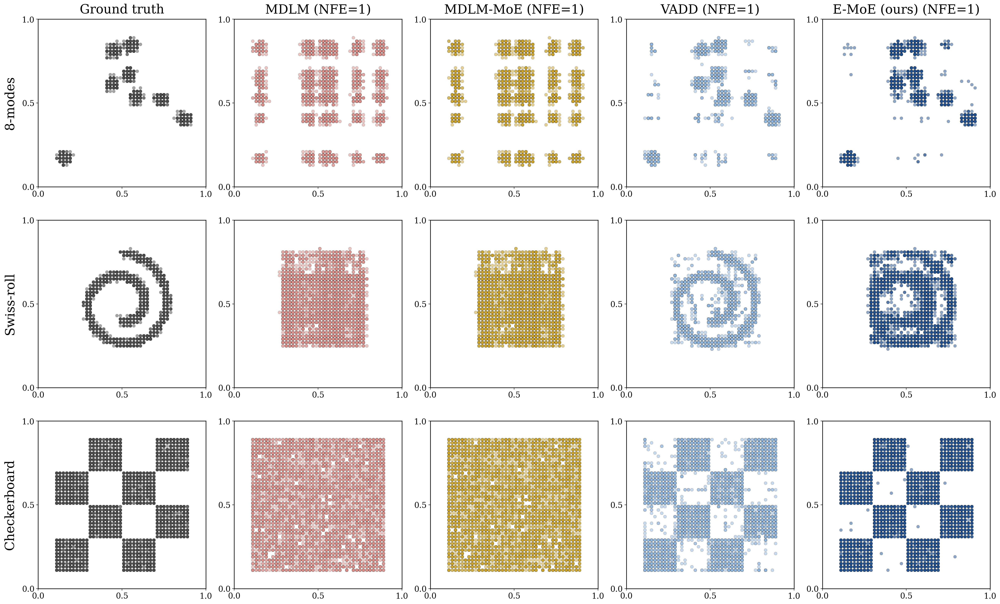

In [15]:
GT_COLOR = '#4a4a4a'
C_MDLM = '#D98C86'
C_VADD = '#8FB5DC'
C_MOE = '#C9A227'
C_EMOE = '#1F4E8C'


def _scatter_panel(ax, tok, V, color, n_show, title='', ylabel='', dot_size=34, alpha=0.5):
    xy = _undiscretise(tok[:n_show], V)
    ax.scatter(xy[:, 0], xy[:, 1], s=dot_size, alpha=alpha, c=color,
              edgecolors='black', linewidths=0.25, rasterized=True)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([0, 0.5, 1])
    ax.set_yticks([0, 0.5, 1])
    ax.tick_params(labelsize=15)
    ax.set_aspect('equal')
    if title:
        ax.set_title(title, fontsize=24, pad=11)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=24, labelpad=11)
    for sp in ax.spines.values():
        sp.set_visible(True)
        sp.set_edgecolor('black')
        sp.set_linewidth(1.2)


MODEL_SPECS = [
    ('MDLM', 'MDLM', C_MDLM),
    ('MDLM-MoE', 'MDLM-MoE', C_MOE),
    ('VADD', 'VADD', C_VADD),
    ('E-MoE (ours)', f'E-MoE/{EMOE_MAIN}', C_EMOE),
]
DEVICE = DEVICES[0]
models_seed0 = {d: {m: load_model(m, d, SEEDS[0]) for _, m, _ in MODEL_SPECS} for d in DATASET_NAMES}

N_SHOW, cell = 6000, 5.2
fig, axes = plt.subplots(len(DATASET_NAMES), 1 + len(MODEL_SPECS),
                         figsize=(cell * (1 + len(MODEL_SPECS)) + 0.5, cell * len(DATASET_NAMES) + 0.8))
for dsi, ds_name in enumerate(DATASET_NAMES):
    ds = DATASETS[ds_name]
    tokens, _ = ds['gen'](20000, SEEDS[0], V=ds['V'], D=2, M=ds['M'])
    _scatter_panel(axes[dsi, 0], tokens.cpu().numpy(), ds['V'], GT_COLOR, N_SHOW,
                   title=('Ground truth' if dsi == 0 else ''), ylabel=DATASET_LABELS[ds_name])
    for j, (name, method, color) in enumerate(MODEL_SPECS, start=1):
        model, c, fn, kw = models_seed0[ds_name][method]
        np.random.seed(42)
        torch.manual_seed(42)
        s = _batched_sample(model, fn, N_SHOW, 1, c, **kw)
        _scatter_panel(axes[dsi, j], s, ds['V'], color, N_SHOW,
                       title=(f'{name} (NFE=1)' if dsi == 0 else ''))
plt.tight_layout()
plt.show()

### Full NFE sweeps

8-modes


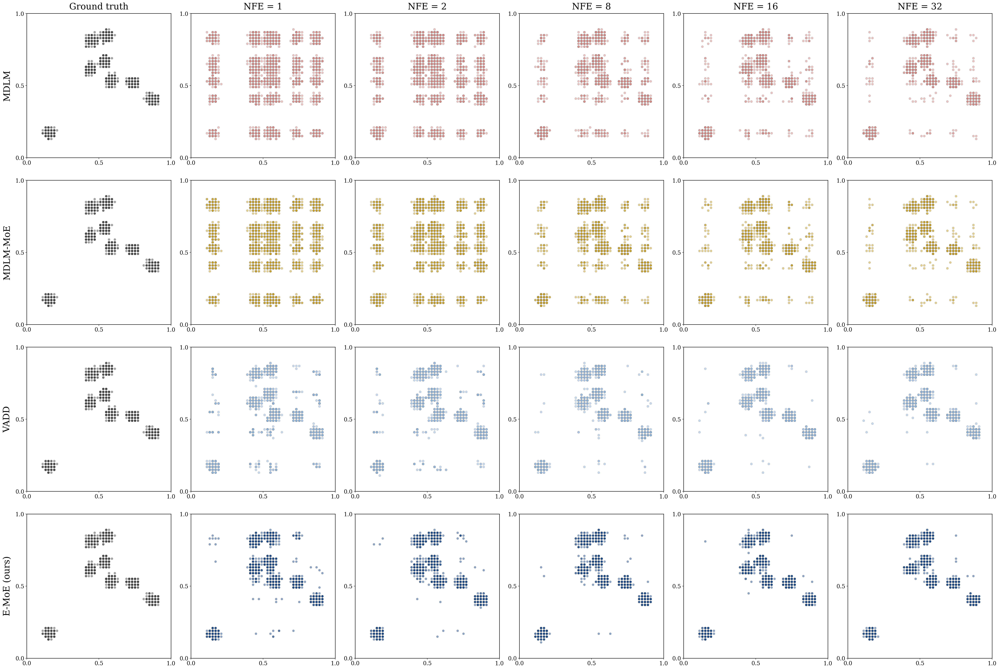

Swiss-roll


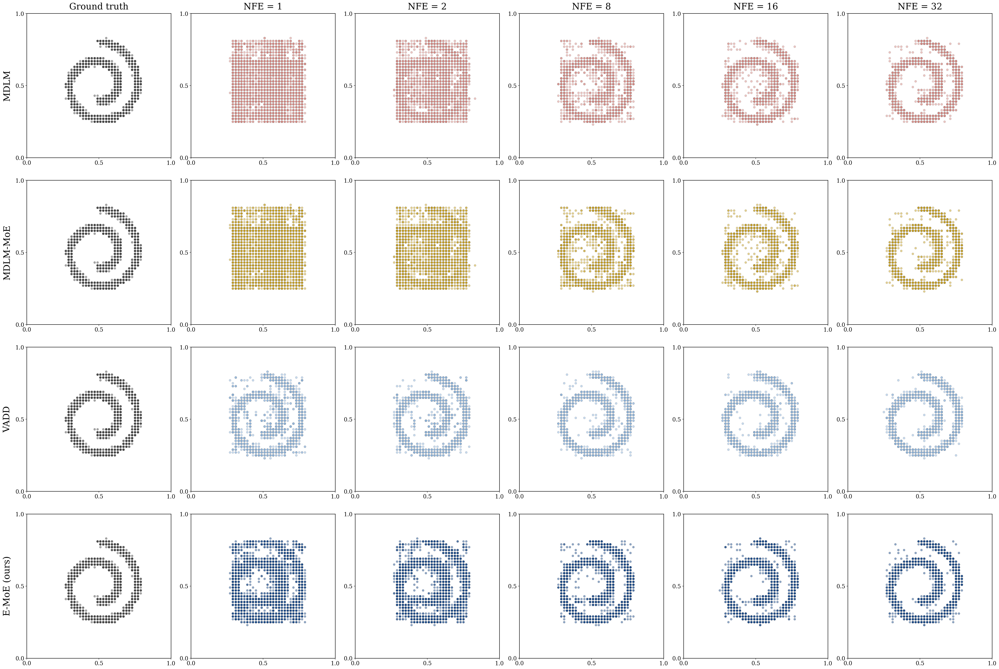

Checkerboard


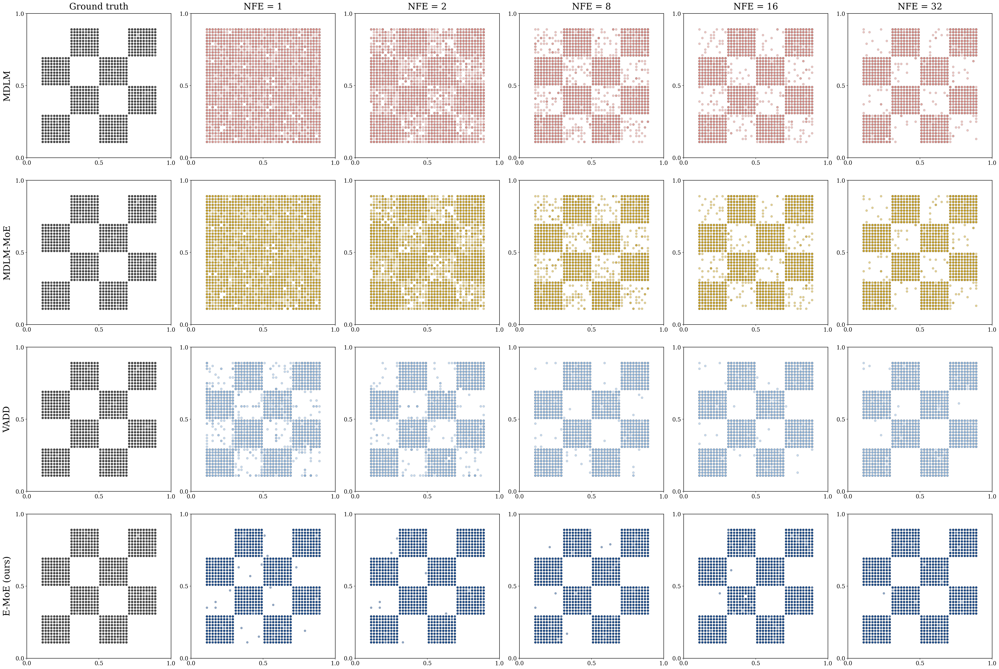

In [16]:
def plot_nfe_grid(train_tokens, model_specs, c, nfe_list=(1, 2, 8, 16, 32), n_samples=6000):
    train_np = train_tokens.cpu().numpy()
    n_show = min(n_samples, train_np.shape[0])
    samples_by_model = {}
    for spec in model_specs:
        nm = spec['name']
        samples_by_model[nm] = {}
        kw = spec.get('sample_kwargs', {})
        for nfe in nfe_list:
            np.random.seed(42)
            torch.manual_seed(42)
            samples_by_model[nm][nfe] = _batched_sample(
                spec['model'], spec['sample_fn'], n_samples, nfe, spec['c'], **kw)
    n_rows = len(model_specs)
    cols = 1 + len(nfe_list)
    cell = 6.2
    fig, axes = plt.subplots(n_rows, cols,
                             figsize=(cell * cols + 0.5, cell * n_rows + 0.8),
                             squeeze=False)

    for r, spec in enumerate(model_specs):
        _scatter_panel(axes[r, 0], train_np, c.V, GT_COLOR, n_show,
                       title=('Ground truth' if r == 0 else ''), ylabel=spec['name'])
        for j, nfe in enumerate(nfe_list, start=1):
            _scatter_panel(axes[r, j], samples_by_model[spec['name']][nfe],
                          c.V, spec['color'], n_show,
                          title=(f'NFE = {nfe}' if r == 0 else ''))
    plt.tight_layout()
    plt.show()


for ds_name in DATASET_NAMES:
    ds = DATASETS[ds_name]
    tokens, _ = ds['gen'](20000, SEEDS[0], V=ds['V'], D=2, M=ds['M'])
    specs = []
    for name, method, color in MODEL_SPECS:
        model, c, fn, kw = models_seed0[ds_name][method]
        specs.append(dict(name=name, color=color, model=model, sample_fn=fn, sample_kwargs=kw, c=c))
    print(DATASET_LABELS[ds_name])
    plot_nfe_grid(tokens.to(DEVICE), specs, specs[0]['c'], nfe_list=(1, 2, 8, 16, 32), n_samples=6000)

### Swiss-roll: E-MoE with free bits

The main E-MoE ($K=16$, $\beta=1$ after warmup) against E-MoE with free bits ($K=8$, KL warmup 30%, free bits 0.5).

In [17]:
FB = f'E-MoE/{EMOE_FREE_BITS}'
FB_ROWS = [('', 'E-MoE (main), K=16, β=1', M), ('', 'E-MoE + free bits 0.5, K=8', FB)]
print('Swiss-roll: validity (%)')
display(table(FB_ROWS, ['swiss_roll'], 'validity'))
print(f"Swiss-roll: TV (TV of original data: {noise_floor['swiss_roll']:.3f})")
display(table(FB_ROWS, ['swiss_roll'], 'tv'))

Swiss-roll: validity (%)


,NFE=1,NFE=2,NFE=4,NFE=8,NFE=16,NFE=32
model,,,,,,
"E-MoE (main), K=16, β=1",80.7 ± 1.9,89.6 ± 1.1,94.0 ± 1.0,96.1 ± 0.4,97.1 ± 0.4,97.8 ± 0.2
"E-MoE + free bits 0.5, K=8",86.9 ± 0.5,92.7 ± 0.5,95.5 ± 0.3,96.6 ± 0.2,97.2 ± 0.5,97.8 ± 0.3


Swiss-roll: TV (TV of original data: 0.048)


,NFE=1,NFE=2,NFE=4,NFE=8,NFE=16,NFE=32
model,,,,,,
"E-MoE (main), K=16, β=1",0.291 ± 0.034,0.154 ± 0.017,0.095 ± 0.007,0.078 ± 0.004,0.070 ± 0.003,0.070 ± 0.002
"E-MoE + free bits 0.5, K=8",0.193 ± 0.006,0.115 ± 0.002,0.085 ± 0.002,0.075 ± 0.001,0.068 ± 0.001,0.070 ± 0.003


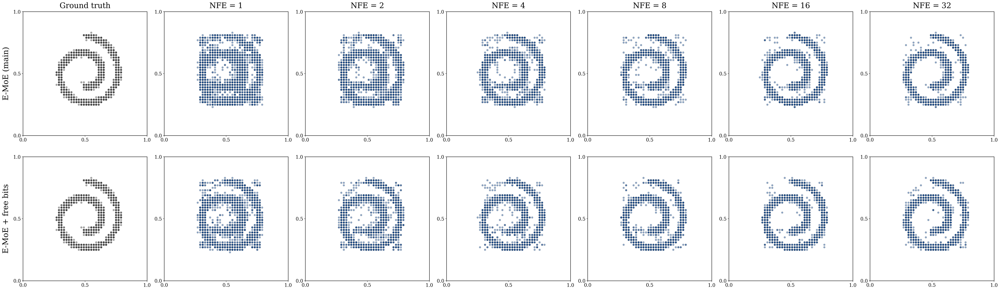

In [18]:
ds = DATASETS['swiss_roll']
tokens, _ = ds['gen'](20000, SEEDS[0], V=ds['V'], D=2, M=ds['M'])
specs = []
for name, method in [('E-MoE (main)', M), ('E-MoE + free bits', FB)]:
    model, c, fn, kw = load_model(method, 'swiss_roll', SEEDS[0])
    specs.append(dict(name=name, color=C_EMOE, model=model, sample_fn=fn, sample_kwargs=kw, c=c))
plot_nfe_grid(tokens.to(DEVICE), specs, specs[0]['c'], nfe_list=(1, 2, 4, 8, 16, 32), n_samples=6000)